# 🎮 VALORANT Personal Coach

## Notebook 01 — Exploratory Data Analysis (Anuj)

### Project Objective

This notebook explores **Anuj's VALORANT Competitive match history** before
machine-learning modelling.

The EDA focuses on:

- dataset structure and data quality,
- Win/Loss/Draw balance,
- agent and map usage,
- role distribution,
- performance by agent, map, and role,
- Agent × Map patterns,
- K/D, ACS and DDΔ distributions,
- monthly performance trends,
- and correlations among numerical match statistics.

The final project is **role-aware**. `Role` is derived from the selected
`Agent`.

`TRS (Tracker Score)` is explored only as part of the original raw-data EDA
and is **not intended to be used as a final modelling feature**.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

## 1. Load Anuj's dataset


In [2]:
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name in [
    "notebooks",
    "DEVnotebooks",
    "ANUJnotebooks",
]:
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "competitive_matches_anuj.xlsx"
)

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Place competitive_matches_anuj.xlsx inside the project data/ folder."
    )

Project root: c:\Users\HP\Desktop\valorant_personal_coach
Dataset path: c:\Users\HP\Desktop\valorant_personal_coach\data\competitive_matches_anuj.xlsx


In [3]:
df = pd.read_excel(
    DATA_PATH,
    sheet_name="Matches",
    header=3,
)

df = df.rename(
    columns={
        "Match ID": "Match id",
        "DDΔ (Per Round)": "DDΔ",
        "DDΔ (Average Damage Delta per Round)": "DDΔ",
        "HS% (Headshot Percentage)": "HS%",
        "ACS (Average Combat Score)": "ACS",
        "TRS (Tracker Score)": "TRS",
    }
)

helper_columns = [
    column
    for column in df.columns
    if (
        str(column).startswith("Unnamed:")
        or str(column).startswith("http://")
        or str(column).startswith("https://")
    )
]

df = (
    df
    .drop(columns=helper_columns, errors="ignore")
    .dropna(how="all")
    .copy()
)

df["Date"] = pd.to_datetime(
    df["Date"],
    errors="coerce",
)

for column in [
    "K/D",
    "ACS",
    "DDΔ",
    "HS%",
    "TRS",
    "Score Margin",
    "Win Flag",
]:
    if column in df.columns:
        df[column] = pd.to_numeric(
            df[column],
            errors="coerce",
        )

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (715, 22)


,Match id,Date,Map,Placement,Agent,Team Score,Opponent Score,Result,Win Flag,Score Margin,...,Deaths,Assists,K/D,Kills/Round,Deaths/Round,Assists/Round,DDΔ,HS%,ACS,TRS
0,1,2026-10-09,Lotus,7th,Cypher,10,13,Loss,0,-3,...,16,4,0.812500,0.565217,0.695652,0.173913,-17,0.06,171,499
1,2,2026-10-09,Sunset,5th,Brimstone,13,7,Win,1,6,...,17,7,0.882353,0.750000,0.850000,0.350000,-21,0.07,221,618
2,3,2026-10-09,Ascent,8th,Cypher,16,14,Win,1,2,...,22,8,0.909091,0.666667,0.733333,0.266667,6,0.07,203,629
3,4,2026-10-09,Ascent,10th,Brimstone,5,13,Loss,0,-8,...,17,3,0.176471,0.166667,0.944444,0.166667,-106,0.10,68,100
4,5,2026-10-08,Sunset,8th,Brimstone,13,11,Win,1,2,...,20,12,0.500000,0.416667,0.833333,0.500000,-53,0.16,132,461


## 2. Dataset structure

In [4]:
print("Number of matches:", len(df))
print("Number of columns:", len(df.columns))

print("\nColumns:")
for column in df.columns:
    print(column)

Number of matches: 715
Number of columns: 22

Columns:
Match id
Date
Map
Placement
Agent
Team Score
Opponent Score
Result
Win Flag
Score Margin
Rounds Played
Kills
Deaths
Assists
K/D
Kills/Round
Deaths/Round
Assists/Round
DDΔ
HS%
ACS
TRS


In [5]:
overview = pd.DataFrame(
    {
        "Data Type": df.dtypes.astype(str),
        "Missing Values": df.isna().sum(),
        "Unique Values": df.nunique(dropna=True),
    }
)

display(overview)

,Data Type,Missing Values,Unique Values
Match id,int64,0,715
Date,datetime64[us],0,105
Map,str,0,10
Placement,str,0,9
Agent,str,0,19
Team Score,int64,0,17
Opponent Score,int64,0,17
Result,str,0,3
Win Flag,int64,0,2
Score Margin,int64,0,25


## 3. Data quality checks

In [6]:
quality_summary = pd.DataFrame(
    {
        "Check": [
            "Total rows",
            "Duplicate rows",
            "Duplicate Match IDs",
            "Missing dates",
            "Missing maps",
            "Missing agents",
            "Missing results",
        ],
        "Value": [
            len(df),
            int(df.duplicated().sum()),
            int(df["Match id"].duplicated().sum()),
            int(df["Date"].isna().sum()),
            int(df["Map"].isna().sum()),
            int(df["Agent"].isna().sum()),
            int(df["Result"].isna().sum()),
        ],
    }
)

display(quality_summary)

print(
    "Date range:",
    df["Date"].min(),
    "to",
    df["Date"].max(),
)

,Check,Value
0,Total rows,715
1,Duplicate rows,0
2,Duplicate Match IDs,0
3,Missing dates,0
4,Missing maps,0
5,Missing agents,0
6,Missing results,0


Date range: 2026-05-20 00:00:00 to 2026-10-09 00:00:00


In [7]:
missing_values = (
    df.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("Missing Values")
)

display(missing_values)

,Missing Values
Match id,0
Date,0
Map,0
Placement,0
Agent,0
Team Score,0
Opponent Score,0
Result,0
Win Flag,0
Score Margin,0


### Note on `Win Flag`

Draws are not part of the later binary Win/Loss target. Therefore, a draw
can legitimately have a missing `Win Flag`.

In [8]:
print("Result counts:")
display(
    df["Result"]
    .value_counts(dropna=False)
    .to_frame("Matches")
)

print("\nWin Flag counts:")
display(
    df["Win Flag"]
    .value_counts(dropna=False)
    .to_frame("Matches")
)

Result counts:


,Matches
Result,
Loss,371
Win,335
Draw,9



Win Flag counts:


,Matches
Win Flag,
0,380
1,335


## 4. Overall result distribution

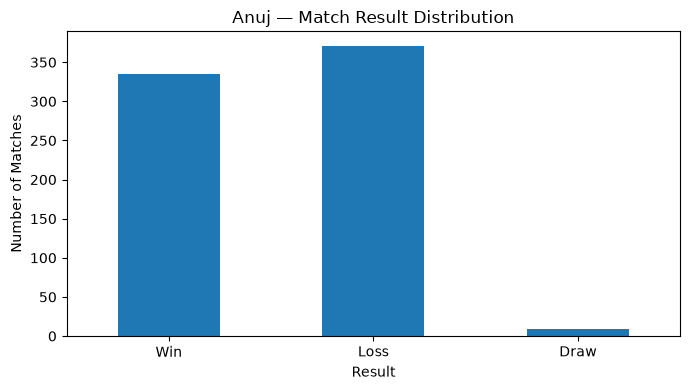

Total matches: 715
Wins: 335
Losses: 371
Draws: 9
Win rate excluding draws: 47.45%


In [9]:
result_counts = (
    df["Result"]
    .value_counts()
    .reindex(["Win", "Loss", "Draw"])
    .dropna()
)

plt.figure(figsize=(7, 4))
result_counts.plot(kind="bar")
plt.title("Anuj — Match Result Distribution")
plt.xlabel("Result")
plt.ylabel("Number of Matches")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

wins = int((df["Result"] == "Win").sum())
losses = int((df["Result"] == "Loss").sum())
draws = int((df["Result"] == "Draw").sum())

binary_matches = wins + losses

win_rate = (
    wins / binary_matches
    if binary_matches
    else np.nan
)

print("Total matches:", len(df))
print("Wins:", wins)
print("Losses:", losses)
print("Draws:", draws)
print(
    "Win rate excluding draws:",
    f"{win_rate:.2%}",
)

## 5. Agent usage

,Matches
Agent,
Cypher,379
Brimstone,97
Neon,49
Viper,45
Tejo,32
Sage,31
Yoru,21
Miks,18
Killjoy,18


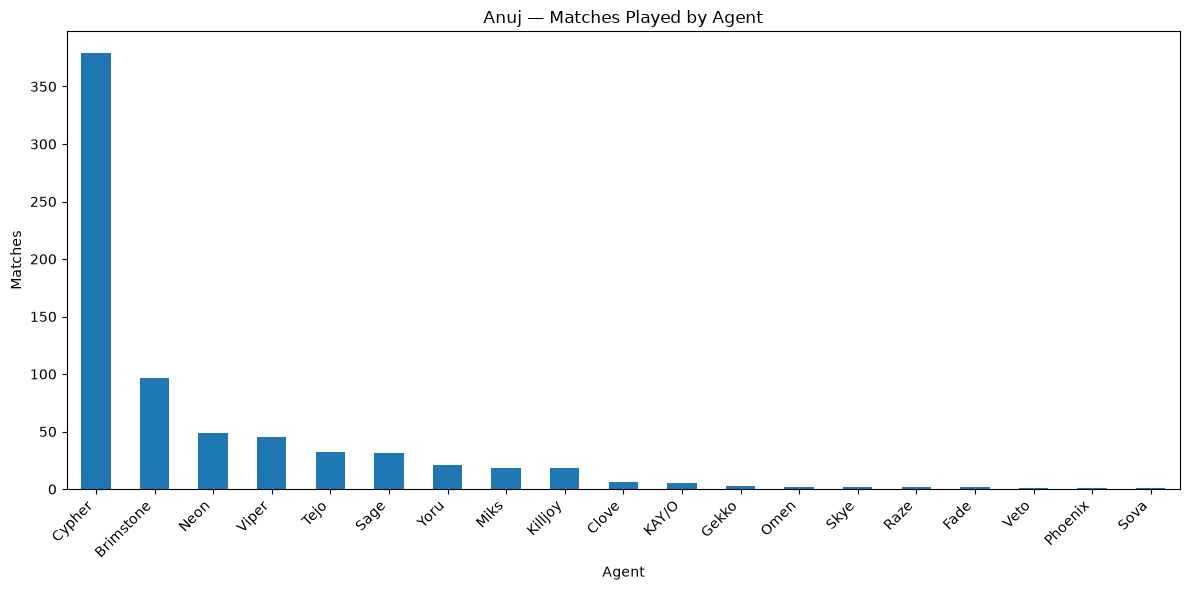

In [10]:
agent_counts = (
    df["Agent"]
    .value_counts()
)

display(
    agent_counts
    .rename("Matches")
    .to_frame()
)

plt.figure(figsize=(12, 6))
agent_counts.plot(kind="bar")
plt.title("Anuj — Matches Played by Agent")
plt.xlabel("Agent")
plt.ylabel("Matches")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 6. Map usage

,Matches
Map,
Ascent,117
Lotus,110
Summit,100
Split,91
Sunset,90
Haven,87
Abyss,61
Breeze,41
Fracture,13


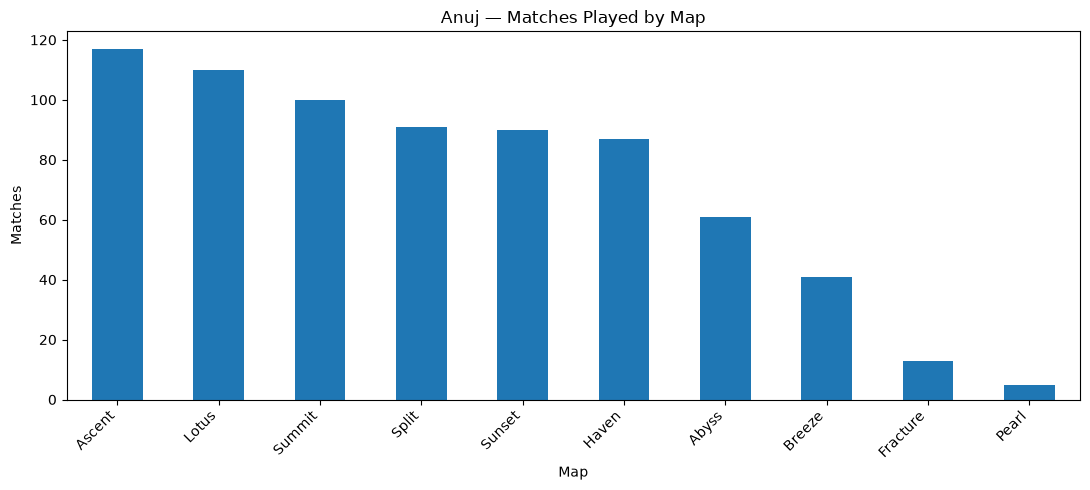

In [11]:
map_counts = (
    df["Map"]
    .value_counts()
)

display(
    map_counts
    .rename("Matches")
    .to_frame()
)

plt.figure(figsize=(11, 5))
map_counts.plot(kind="bar")
plt.title("Anuj — Matches Played by Map")
plt.xlabel("Map")
plt.ylabel("Matches")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 7. Role-aware EDA

The raw dataset does not contain a Role column.

Role is therefore derived using the official Agent → Role mapping.

**Agent determines the role. ACS does not determine the role.**

In [12]:
AGENT_ROLE_MAP = {
    # Duelists
    "Iso": "Duelist",
    "Jett": "Duelist",
    "Neon": "Duelist",
    "Phoenix": "Duelist",
    "Raze": "Duelist",
    "Reyna": "Duelist",
    "Waylay": "Duelist",
    "Yoru": "Duelist",

    # Controllers
    "Astra": "Controller",
    "Brimstone": "Controller",
    "Clove": "Controller",
    "Harbor": "Controller",
    "Miks": "Controller",
    "Omen": "Controller",
    "Viper": "Controller",

    # Initiators
    "Breach": "Initiator",
    "Fade": "Initiator",
    "Gekko": "Initiator",
    "KAY/O": "Initiator",
    "Skye": "Initiator",
    "Sova": "Initiator",
    "Tejo": "Initiator",

    # Sentinels
    "Chamber": "Sentinel",
    "Cypher": "Sentinel",
    "Deadlock": "Sentinel",
    "Killjoy": "Sentinel",
    "Sage": "Sentinel",
    "Veto": "Sentinel",
    "Vyse": "Sentinel",
}

df["Role"] = (
    df["Agent"]
    .map(AGENT_ROLE_MAP)
)

unknown_agents = (
    df.loc[
        df["Role"].isna(),
        "Agent",
    ]
    .dropna()
    .unique()
    .tolist()
)

print("Unknown agents:", unknown_agents)

role_distribution = (
    df["Role"]
    .value_counts(dropna=False)
)

display(
    role_distribution
    .rename("Matches")
    .to_frame()
)

Unknown agents: []


,Matches
Role,
Sentinel,429
Controller,168
Duelist,73
Initiator,45


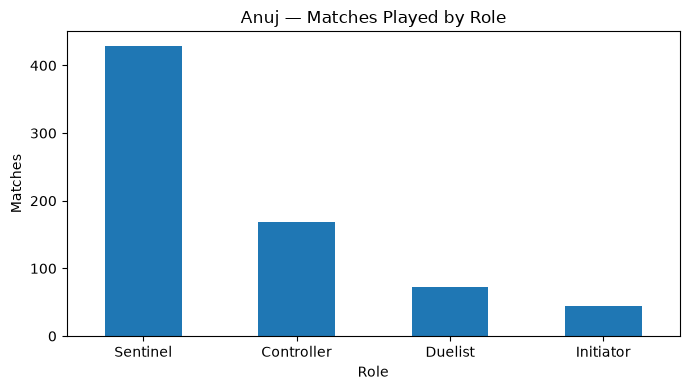

In [13]:
role_counts = (
    df["Role"]
    .value_counts()
)

plt.figure(figsize=(7, 4))
role_counts.plot(kind="bar")
plt.title("Anuj — Matches Played by Role")
plt.xlabel("Role")
plt.ylabel("Matches")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 8. Performance by Agent

Win rate is calculated using Win/Loss matches only. Draws are excluded from
the denominator.

In [14]:
binary_df = (
    df[df["Result"].isin(["Win", "Loss"])]
    .copy()
)

binary_df["Win"] = (
    binary_df["Result"] == "Win"
).astype(int)

agent_performance = (
    binary_df
    .groupby("Agent")
    .agg(
        Matches=("Match id", "count"),
        Wins=("Win", "sum"),
        Win_Rate=("Win", "mean"),
        Avg_KD=("K/D", "mean"),
        Avg_ACS=("ACS", "mean"),
        Avg_DD_Delta=("DDΔ", "mean"),
    )
    .sort_values(
        ["Win_Rate", "Matches"],
        ascending=[False, False],
    )
)

display(
    agent_performance.style.format(
        {
            "Win_Rate": "{:.2%}",
            "Avg_KD": "{:.2f}",
            "Avg_ACS": "{:.1f}",
            "Avg_DD_Delta": "{:.1f}",
        }
    )
)

,Matches,Wins,Win_Rate,Avg_KD,Avg_ACS,Avg_DD_Delta
Agent,,,,,,
Omen,2,2,100.00%,0.66,118.5,-36.5
Killjoy,18,12,66.67%,1.05,181.2,5.2
Gekko,3,2,66.67%,0.66,144.0,-26.0
KAY/O,5,3,60.00%,0.59,154.0,-27.2
Yoru,21,11,52.38%,0.86,186.3,-5.2
Miks,18,9,50.00%,1.13,188.0,-10.3
Fade,2,1,50.00%,1.39,178.5,21.0
Raze,2,1,50.00%,0.62,169.0,-27.0
Skye,2,1,50.00%,0.61,149.5,-41.0


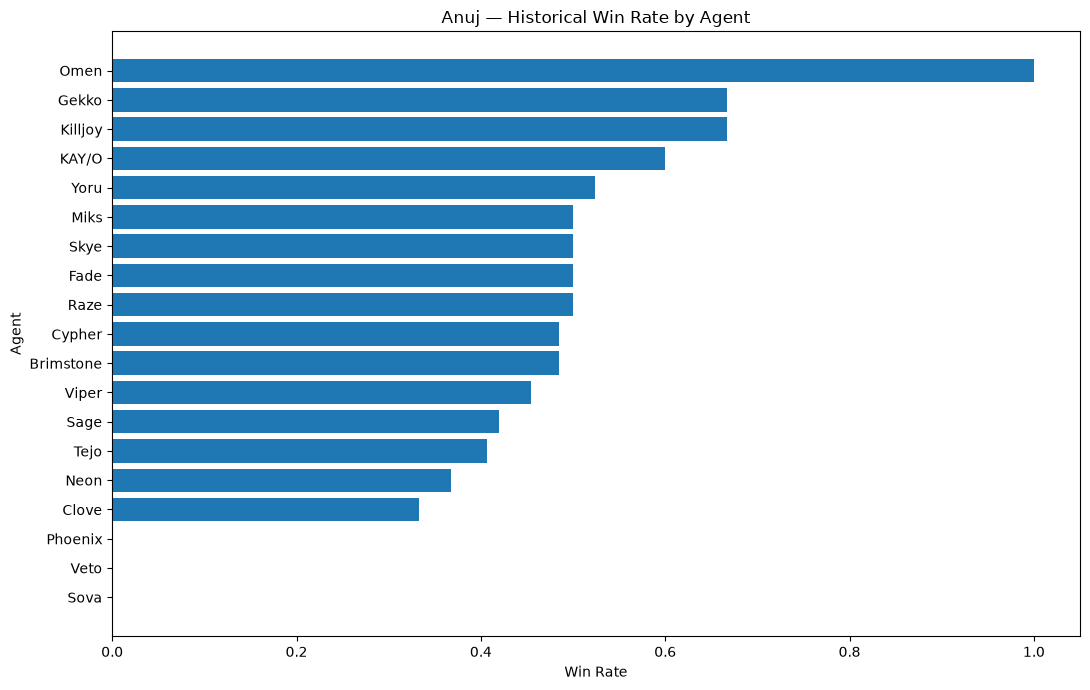

In [15]:
agent_plot = (
    agent_performance
    .sort_values("Win_Rate")
)

plt.figure(figsize=(11, 7))
plt.barh(
    agent_plot.index,
    agent_plot["Win_Rate"],
)
plt.title("Anuj — Historical Win Rate by Agent")
plt.xlabel("Win Rate")
plt.ylabel("Agent")
plt.tight_layout()
plt.show()

## 9. Performance by Map

In [16]:
map_performance = (
    binary_df
    .groupby("Map")
    .agg(
        Matches=("Match id", "count"),
        Wins=("Win", "sum"),
        Win_Rate=("Win", "mean"),
        Avg_KD=("K/D", "mean"),
        Avg_ACS=("ACS", "mean"),
        Avg_DD_Delta=("DDΔ", "mean"),
    )
    .sort_values(
        ["Win_Rate", "Matches"],
        ascending=[False, False],
    )
)

display(
    map_performance.style.format(
        {
            "Win_Rate": "{:.2%}",
            "Avg_KD": "{:.2f}",
            "Avg_ACS": "{:.1f}",
            "Avg_DD_Delta": "{:.1f}",
        }
    )
)

,Matches,Wins,Win_Rate,Avg_KD,Avg_ACS,Avg_DD_Delta
Map,,,,,,
Pearl,4,3,75.00%,1.10,210.5,11.2
Haven,86,49,56.98%,1.01,198.2,5.1
Summit,100,53,53.00%,0.97,194.4,-5.4
Abyss,59,28,47.46%,0.91,178.6,-6.4
Split,89,42,47.19%,0.82,171.6,-13.2
Sunset,89,42,47.19%,0.90,192.8,-11.4
Ascent,117,54,46.15%,0.91,188.3,-6.9
Lotus,108,47,43.52%,0.86,178.9,-13.4
Breeze,41,13,31.71%,0.87,194.1,-5.2


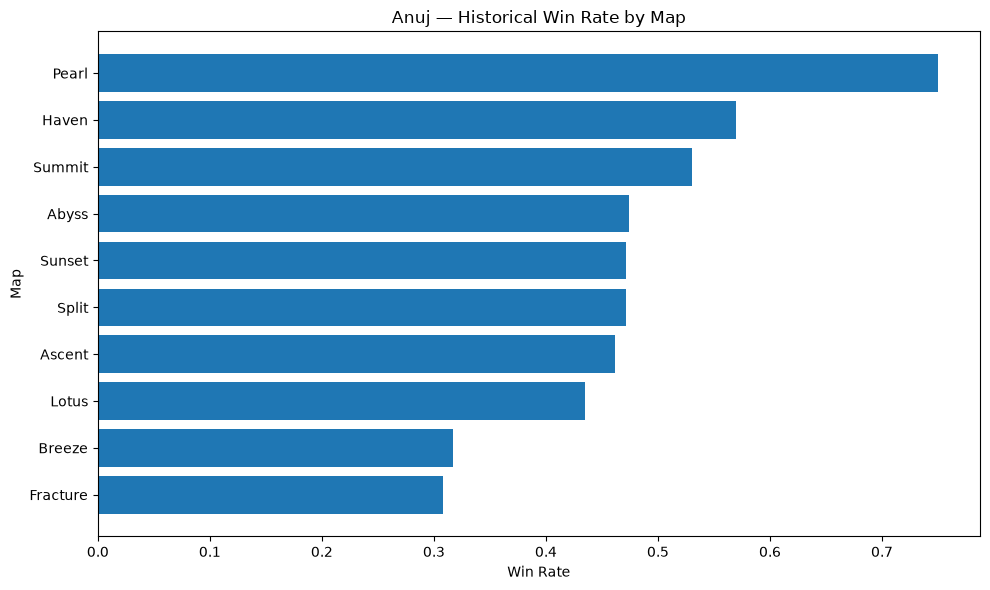

In [17]:
map_plot = (
    map_performance
    .sort_values("Win_Rate")
)

plt.figure(figsize=(10, 6))
plt.barh(
    map_plot.index,
    map_plot["Win_Rate"],
)
plt.title("Anuj — Historical Win Rate by Map")
plt.xlabel("Win Rate")
plt.ylabel("Map")
plt.tight_layout()
plt.show()

## 10. Performance by Role

In [18]:
role_performance = (
    binary_df
    .groupby("Role")
    .agg(
        Matches=("Match id", "count"),
        Wins=("Win", "sum"),
        Win_Rate=("Win", "mean"),
        Avg_KD=("K/D", "mean"),
        Avg_ACS=("ACS", "mean"),
    )
    .sort_values(
        ["Win_Rate", "Matches"],
        ascending=[False, False],
    )
)

display(
    role_performance.style.format(
        {
            "Win_Rate": "{:.2%}",
            "Avg_KD": "{:.2f}",
            "Avg_ACS": "{:.1f}",
        }
    )
)

,Matches,Wins,Win_Rate,Avg_KD,Avg_ACS
Role,,,,,
Sentinel,421,205,48.69%,0.93,186.0
Controller,167,80,47.90%,0.95,193.8
Initiator,45,20,44.44%,0.87,181.9
Duelist,73,30,41.10%,0.77,182.2


## 11. Agent × Map analysis

This section looks at combinations Anuj has actually played.

Very small samples should be interpreted carefully.

In [19]:
agent_map_performance = (
    binary_df
    .groupby(["Agent", "Map"])
    .agg(
        Matches=("Match id", "count"),
        Wins=("Win", "sum"),
        Win_Rate=("Win", "mean"),
        Avg_KD=("K/D", "mean"),
        Avg_ACS=("ACS", "mean"),
    )
    .reset_index()
    .sort_values(
        ["Matches", "Win_Rate"],
        ascending=[False, False],
    )
)

display(
    agent_map_performance
    .head(40)
    .style.format(
        {
            "Win_Rate": "{:.2%}",
            "Avg_KD": "{:.2f}",
            "Avg_ACS": "{:.1f}",
        }
    )
)

,Agent,Map,Matches,Wins,Win_Rate,Avg_KD,Avg_ACS
13,Cypher,Ascent,96,44,45.83%,0.96,194.5
19,Cypher,Split,70,31,44.29%,0.83,175.7
16,Cypher,Haven,68,40,58.82%,1.01,195.4
6,Brimstone,Summit,44,21,47.73%,1.01,207.6
76,Viper,Lotus,38,19,50.00%,0.99,197.4
12,Cypher,Abyss,35,16,45.71%,0.94,190.4
7,Brimstone,Sunset,28,16,57.14%,0.97,198.4
17,Cypher,Lotus,27,13,48.15%,0.84,174.8
21,Cypher,Sunset,27,13,48.15%,0.89,183.6
20,Cypher,Summit,22,13,59.09%,1.02,193.4


In [20]:
stable_agent_map = (
    agent_map_performance[
        agent_map_performance["Matches"] >= 5
    ]
    .sort_values(
        ["Win_Rate", "Matches"],
        ascending=[False, False],
    )
)

print(
    "Agent × Map combinations with at least 5 matches:",
    len(stable_agent_map),
)

display(
    stable_agent_map
    .head(30)
    .style.format(
        {
            "Win_Rate": "{:.2%}",
            "Avg_KD": "{:.2f}",
            "Avg_ACS": "{:.1f}",
        }
    )
)

Agent × Map combinations with at least 5 matches: 27


,Agent,Map,Matches,Wins,Win_Rate,Avg_KD,Avg_ACS
62,Sage,Summit,8,5,62.50%,0.78,169.6
41,Miks,Haven,5,3,60.00%,1.29,230.8
20,Cypher,Summit,22,13,59.09%,1.02,193.4
16,Cypher,Haven,68,40,58.82%,1.01,195.4
7,Brimstone,Sunset,28,16,57.14%,0.97,198.4
0,Brimstone,Abyss,7,4,57.14%,0.72,164.9
1,Brimstone,Ascent,7,4,57.14%,0.93,191.9
57,Sage,Abyss,9,5,55.56%,1.12,156.7
76,Viper,Lotus,38,19,50.00%,0.99,197.4
52,Neon,Sunset,12,6,50.00%,0.91,209.6


## 12. Performance distributions

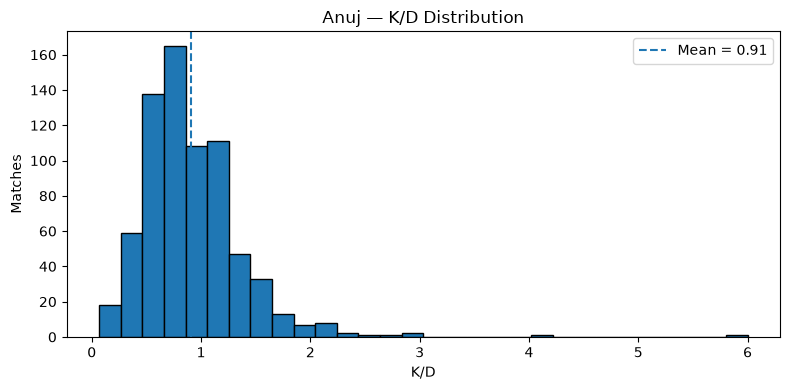

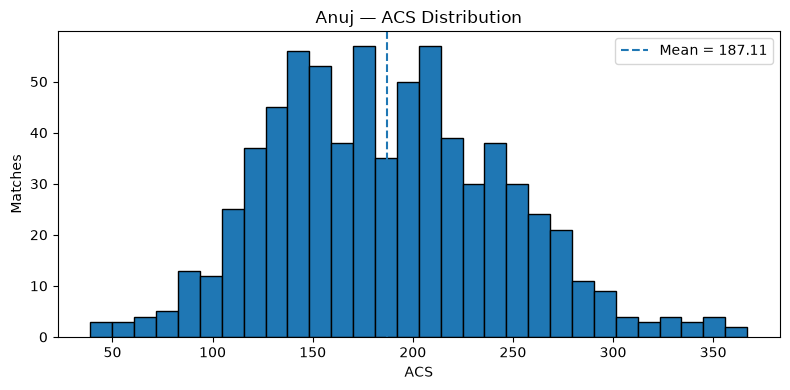

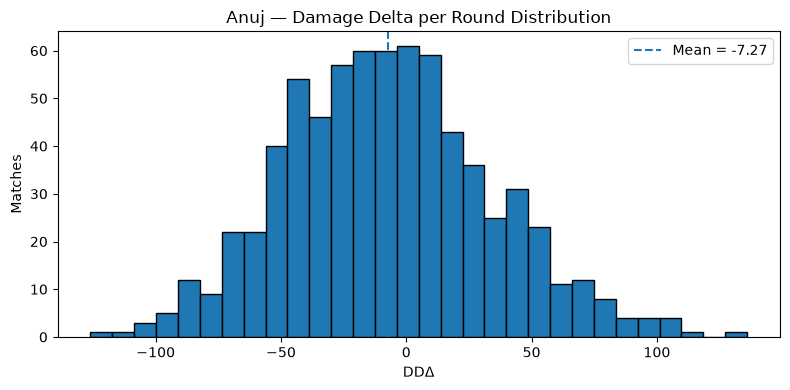

In [21]:
metrics = [
    ("K/D", "K/D Distribution"),
    ("ACS", "ACS Distribution"),
    ("DDΔ", "Damage Delta per Round Distribution"),
]

for column, title in metrics:

    values = pd.to_numeric(
        df[column],
        errors="coerce",
    ).dropna()

    plt.figure(figsize=(8, 4))
    plt.hist(
        values,
        bins=30,
        edgecolor="black",
    )

    plt.axvline(
        values.mean(),
        linestyle="--",
        label=f"Mean = {values.mean():.2f}",
    )

    plt.title(
        f"Anuj — {title}"
    )

    plt.xlabel(column)
    plt.ylabel("Matches")
    plt.legend()
    plt.tight_layout()
    plt.show()

## 13. Wins vs Losses performance comparison

In [22]:
comparison_columns = [
    "Kills",
    "Deaths",
    "Assists",
    "K/D",
    "ACS",
    "DDΔ",
    "HS%",
    "Score Margin",
]

result_comparison = (
    df[df["Result"].isin(["Win", "Loss"])]
    .groupby("Result")[comparison_columns]
    .mean(numeric_only=True)
    .T
)

display(
    result_comparison.style.format(
        "{:.2f}"
    )
)

Result,Loss,Win
Kills,12.12,14.14
Deaths,16.64,13.97
Assists,4.12,5.18
K/D,0.74,1.11
ACS,178.65,196.64
DDΔ,-20.68,7.80
HS%,0.11,0.11
Score Margin,-5.60,5.16


## 14. Numerical correlations

Correlation is descriptive and does not imply causation.

`TRS` is shown here only because it exists in the raw dataset. It should not
be passed into the final pre-match ML pipeline.

In [23]:
correlation_columns = [
    "Kills",
    "Deaths",
    "Assists",
    "K/D",
    "Kills/Round",
    "Deaths/Round",
    "Assists/Round",
    "DDΔ",
    "HS%",
    "ACS",
    "TRS",
    "Score Margin",
    "Win Flag",
]

correlation_columns = [
    column
    for column in correlation_columns
    if column in df.columns
]

correlation_df = (
    df[correlation_columns]
    .apply(
        pd.to_numeric,
        errors="coerce",
    )
    .corr()
)

display(
    correlation_df.round(2)
)

,Kills,Deaths,Assists,K/D,Kills/Round,Deaths/Round,Assists/Round,DDΔ,HS%,ACS,TRS,Score Margin,Win Flag
Kills,1.00,0.17,0.18,0.60,0.86,-0.24,0.04,0.71,0.08,0.84,0.72,0.24,0.19
Deaths,0.17,1.00,0.20,-0.53,-0.23,0.69,-0.07,-0.40,-0.09,-0.14,-0.37,-0.38,-0.37
Assists,0.18,0.20,1.00,0.03,0.04,-0.07,0.92,0.14,0.05,0.13,0.26,0.22,0.19
K/D,0.60,-0.53,0.03,1.00,0.82,-0.69,0.14,0.81,0.13,0.73,0.80,0.47,0.38
Kills/Round,0.86,-0.23,0.04,0.82,1.00,-0.34,0.07,0.85,0.10,0.96,0.84,0.28,0.23
Deaths/Round,-0.24,0.69,-0.07,-0.69,-0.34,1.00,-0.14,-0.57,-0.13,-0.23,-0.58,-0.68,-0.58
Assists/Round,0.04,-0.07,0.92,0.14,0.07,-0.14,1.00,0.18,0.05,0.15,0.30,0.25,0.22
DDΔ,0.71,-0.40,0.14,0.81,0.85,-0.57,0.18,1.00,0.15,0.86,0.89,0.41,0.34
HS%,0.08,-0.09,0.05,0.13,0.10,-0.13,0.05,0.15,1.00,0.08,0.13,0.08,0.05
ACS,0.84,-0.14,0.13,0.73,0.96,-0.23,0.15,0.86,0.08,1.00,0.82,0.20,0.16


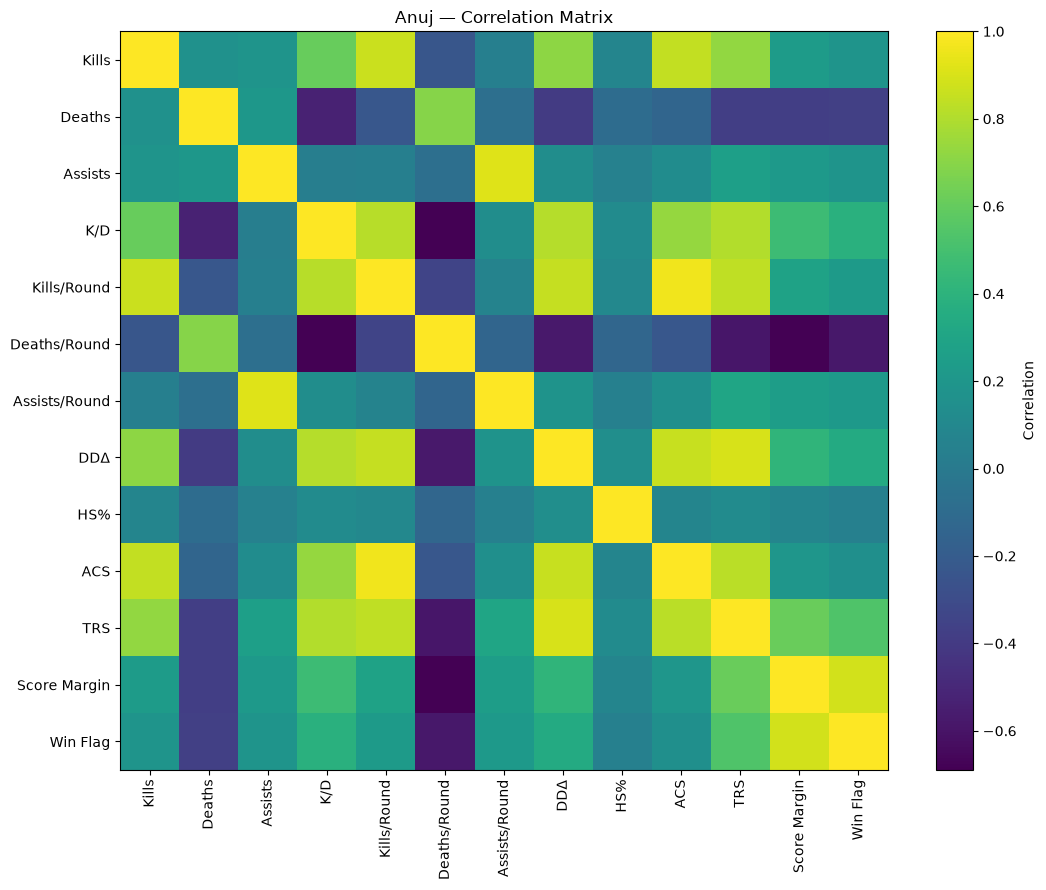

In [24]:
fig, ax = plt.subplots(
    figsize=(11, 9)
)

image = ax.imshow(
    correlation_df.values,
    aspect="auto",
)

ax.set_xticks(
    range(len(correlation_df.columns))
)
ax.set_yticks(
    range(len(correlation_df.index))
)

ax.set_xticklabels(
    correlation_df.columns,
    rotation=90,
)
ax.set_yticklabels(
    correlation_df.index,
)

ax.set_title(
    "Anuj — Correlation Matrix"
)

fig.colorbar(
    image,
    ax=ax,
    label="Correlation",
)

plt.tight_layout()
plt.show()

## 15. Monthly performance trend

In [25]:
monthly = (
    binary_df
    .set_index("Date")
    .resample("MS")
    .agg(
        Matches=("Match id", "count"),
        Win_Rate=("Win", "mean"),
        Avg_KD=("K/D", "mean"),
        Avg_ACS=("ACS", "mean"),
    )
)

monthly = (
    monthly[
        monthly["Matches"] > 0
    ]
)

display(
    monthly.style.format(
        {
            "Win_Rate": "{:.2%}",
            "Avg_KD": "{:.2f}",
            "Avg_ACS": "{:.1f}",
        }
    )
)

,Matches,Win_Rate,Avg_KD,Avg_ACS
Date,,,,
2026-05-01 00:00:00,80,40.00%,0.90,186.0
2026-07-01 00:00:00,152,44.08%,0.81,181.1
2026-08-01 00:00:00,186,47.85%,0.95,191.0
2026-09-01 00:00:00,195,49.23%,0.98,195.5
2026-10-01 00:00:00,93,54.84%,0.86,172.9


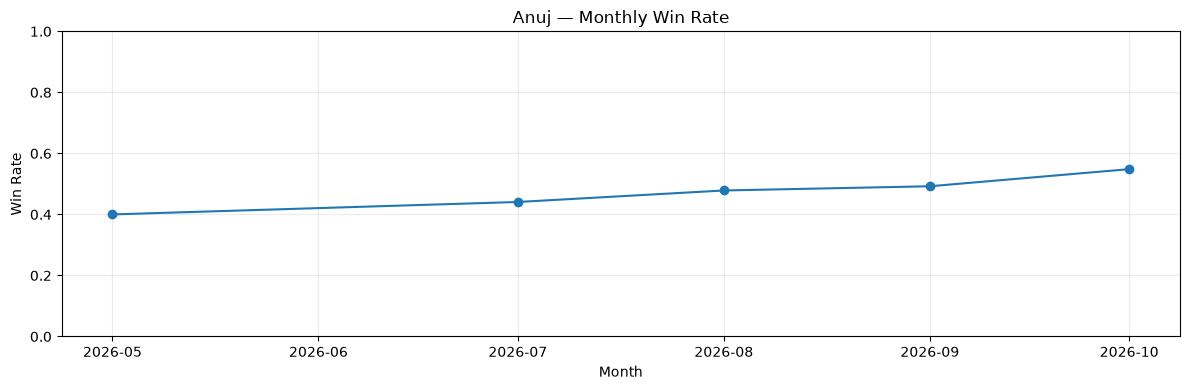

In [26]:
plt.figure(figsize=(12, 4))

plt.plot(
    monthly.index,
    monthly["Win_Rate"],
    marker="o",
)

plt.title(
    "Anuj — Monthly Win Rate"
)

plt.xlabel("Month")
plt.ylabel("Win Rate")
plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 16. Highest and lowest K/D matches

In [27]:
display_columns = [
    "Date",
    "Map",
    "Agent",
    "Role",
    "Result",
    "Kills",
    "Deaths",
    "Assists",
    "K/D",
    "ACS",
    "DDΔ",
]

print("Highest K/D matches:")
display(
    df.nlargest(
        10,
        "K/D",
    )[display_columns]
)

print("\nLowest K/D matches:")
display(
    df.nsmallest(
        10,
        "K/D",
    )[display_columns]
)

Highest K/D matches:


,Date,Map,Agent,Role,Result,Kills,Deaths,Assists,K/D,ACS,DDΔ
463,2026-08-03,Summit,Miks,Controller,Win,6,1,3,6.000000,272,69
201,2026-09-17,Abyss,Sage,Sentinel,Win,21,5,8,4.200000,292,80
225,2026-09-13,Ascent,Cypher,Sentinel,Win,15,5,7,3.000000,367,136
422,2026-08-09,Ascent,Cypher,Sentinel,Win,12,4,2,3.000000,265,80
264,2026-09-07,Lotus,Viper,Controller,Win,17,6,2,2.833333,290,94
323,2026-08-27,Abyss,Cypher,Sentinel,Win,21,8,4,2.625000,272,104
189,2026-09-19,Summit,Brimstone,Controller,Win,16,7,5,2.285714,283,67
262,2026-09-07,Lotus,Tejo,Initiator,Win,18,8,5,2.250000,277,91
21,2026-10-07,Haven,Cypher,Sentinel,Win,20,9,2,2.222222,261,87
343,2026-08-25,Haven,Cypher,Sentinel,Win,20,9,7,2.222222,331,110



Lowest K/D matches:


,Date,Map,Agent,Role,Result,Kills,Deaths,Assists,K/D,ACS,DDΔ
139,2026-09-25,Ascent,Sage,Sentinel,Loss,1,15,4,0.066667,44,-115
684,2026-05-22,Split,Cypher,Sentinel,Loss,2,18,4,0.111111,39,-104
310,2026-08-29,Split,Cypher,Sentinel,Loss,2,12,3,0.166667,57,-87
544,2026-07-19,Split,Cypher,Sentinel,Win,3,18,6,0.166667,61,-71
3,2026-10-09,Ascent,Brimstone,Controller,Loss,3,17,3,0.176471,68,-106
71,2026-10-03,Haven,Cypher,Sentinel,Loss,3,17,3,0.176471,48,-126
418,2026-08-10,Breeze,Cypher,Sentinel,Loss,3,17,3,0.176471,73,-92
426,2026-08-09,Ascent,Cypher,Sentinel,Loss,3,17,2,0.176471,80,-79
106,2026-09-29,Lotus,Viper,Controller,Loss,3,16,1,0.187500,54,-108
348,2026-08-24,Lotus,Viper,Controller,Win,4,19,8,0.210526,65,-76


## 17. Anuj Dataset Summary

Anuj's dataset contains **715 Competitive matches**, including a large
Sentinel history led by Cypher together with substantial Controller usage.

Important modelling implications:

1. Agent usage is imbalanced, so frequently played agents have more reliable
   historical information than rarely used agents.
2. Role usage is also imbalanced, supporting the final **Top 2 agents per
   role** recommendation design.
3. Map history is substantial enough to support personalized map-aware
   historical features.
4. Agent × Map combinations with small samples should still be interpreted
   cautiously.
5. Current-match K/D, ACS, kills, deaths, DDΔ and TRS are useful for EDA but
   cannot be used directly as pre-match model inputs.
6. The later feature-engineering pipeline should create only
   **historical, leakage-free versions** of performance information.

The next stage is the common cleaning and historical feature-engineering
pipeline, followed by separate Logistic Regression, Random Forest and
CatBoost modelling notebooks.